# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()`
2. **Validate** — `val.sweep(goal)` for metrics; `val.validate(goal, n=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Metrics are reported per isobath depth, mesh polygon, and buoy.

In [1]:
import matplotlib.pyplot as plt
from utils import metamodel as mm
from utils import validation as val
from utils.config import METAMODEL, load_goals, mda_max_points

In [2]:
goals = list(load_goals().keys())
candidates = METAMODEL["mda_candidates"]

print(f"goals      : {goals}")
print(f"candidates : {candidates}")
print(f"MDA max    : {mda_max_points()} (test cases = 500 - max)")
print(f"Hs filter  : > {METAMODEL['site_filter']['hs_max']} m removed before PCA")

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11']
candidates : [25, 50, 100, 150, 200, 250, 300, 350, 400, 450]
MDA max    : 450 (test cases = 500 - max)
Hs filter  : > 10.0 m removed before PCA


## 1. Fit

In [4]:
goal = "1"

# One goal — all MDA candidate sizes from config
# mm.fit(goal, gp_epochs=1000)

In [ ]:
# All goals:
mm.fit_all(gp_epochs=1000)

## 2. Validate

In [5]:
# Metrics for every MDA size → outputs/goal_01/validation_metrics.csv
metrics = val.sweep(goal)
metrics

2026-06-26 13:10:55,539 - Samoa.validation - INFO - Goal 1: validating n=25
INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for wl is bigger than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for wl is lower than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for dir_u is lower than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: PC1
INFO:ExactGPInterpolation:Predicting target variable: PC2
INFO:ExactGPInterpolation:Predicting target variable: PC3
INFO:ExactGPInterpolation:Predicting target variable: PC4
INFO:ExactGPInterpolation:Predicting target variable: PC5
INFO:

,goal,mda_candidate,n_test_cases,group,site_source,site_label,variable,label,n,bias,rmse,r2
0,1,25,50,5m,isobath,5m,hs,Hs,4600,-0.015465,0.087316,0.673366
1,1,25,50,5m,isobath,5m,tp,Tp,4600,-0.010744,0.397697,0.993218
2,1,25,50,5m,isobath,5m,dir,Dir,4600,-1.238384,18.485653,0.910890
3,1,25,50,10m,isobath,10m,hs,Hs,5150,-0.011501,0.077231,0.718088
4,1,25,50,10m,isobath,10m,tp,Tp,5150,-0.011704,0.415069,0.991434
...,...,...,...,...,...,...,...,...,...,...,...,...
265,1,450,50,buoy_American_Samoa_Buoy,buoy,waves,tp,Tp,50,-0.008763,0.059571,0.999799
266,1,450,50,buoy_American_Samoa_Buoy,buoy,waves,dir,Dir,50,-1.505359,11.150842,0.959565
267,1,450,50,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,50,0.000332,0.022958,0.925541
268,1,450,50,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,50,-0.008763,0.059571,0.999799


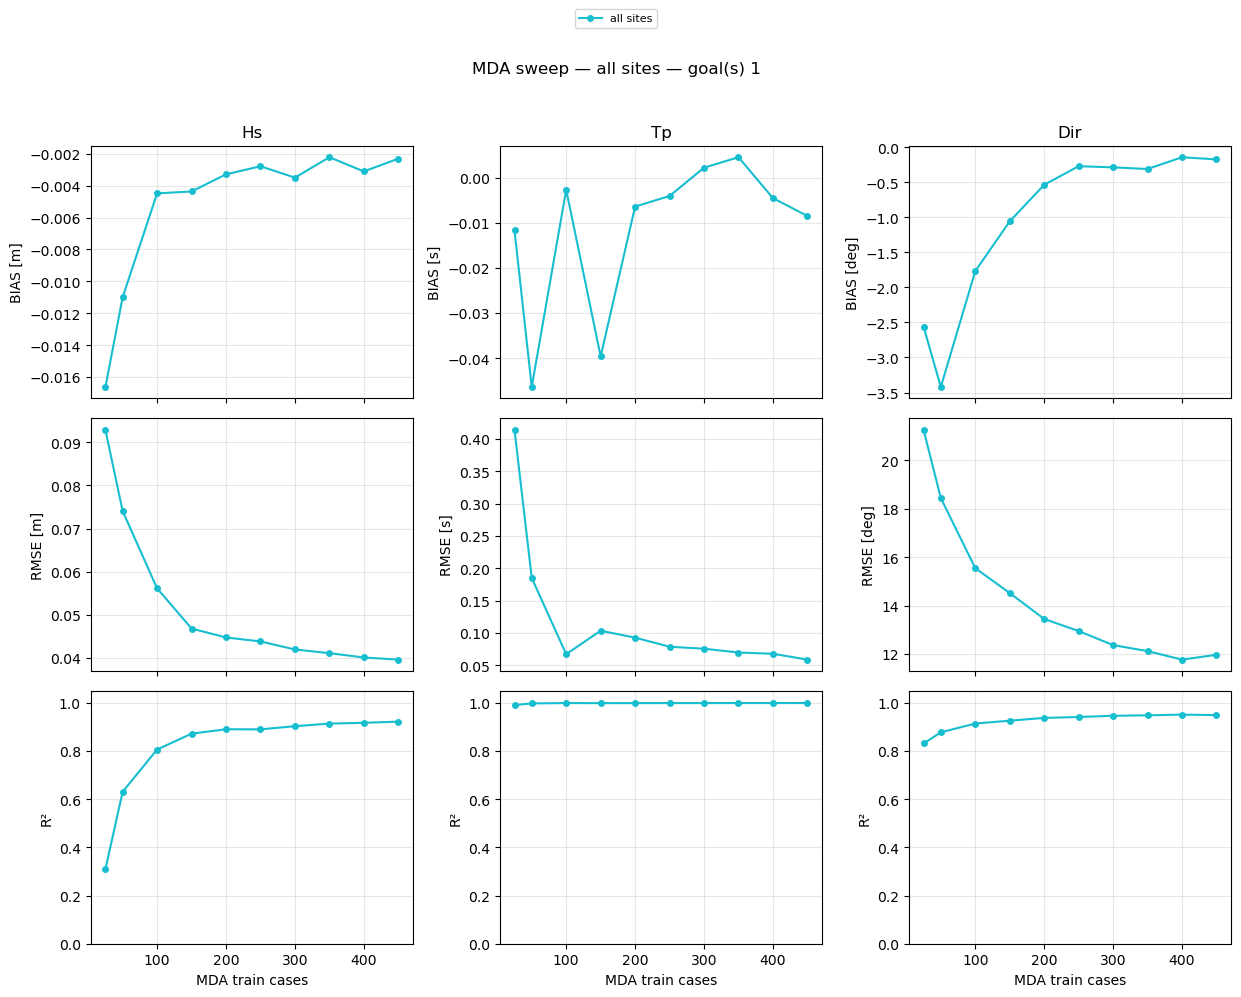

In [7]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3. Plot

In [16]:
n = 450  # MDA size to plot
result = val.validate(goal, n)

# Available groups: isobath depths, mesh labels, buoy ids
[g[0] for g in val.metric_groups(result.estimate)]

2026-06-26 12:21:34,500 - Samoa.validation - INFO - Computed 27 validation metric row(s)


['5m',
 '10m',
 '20m',
 '50m',
 'Apia',
 'buoy_Apolima_Buoy',
 'buoy_Apolima_Javi_Buoy',
 'buoy_American_Samoa_Buoy',
 'buoy_Aunuu_Buoy']

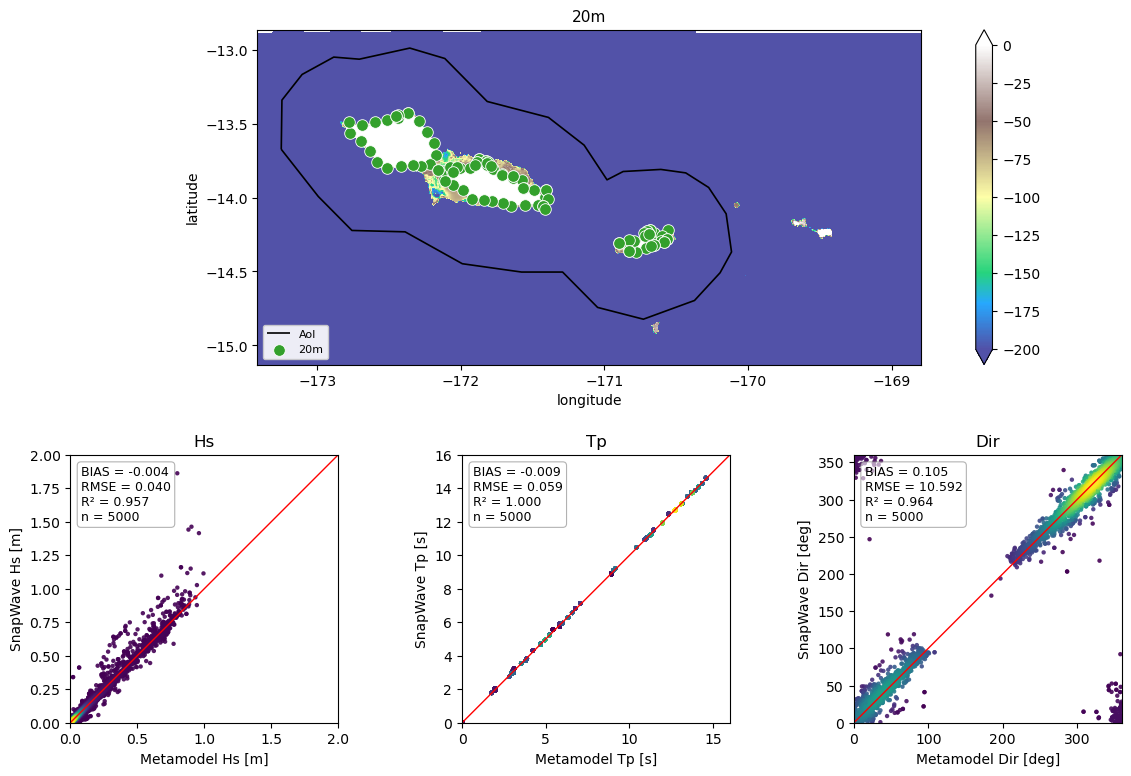

In [21]:
result.plot("20m")
plt.show()

In [ ]:
# Map only, or scatters only
# result.plot_map("10m")
# result.plot_scatter("10m", variables=["hs"])

# All groups (optionally filter variables or groups)
for fig in result.plot_all(variables=["hs", "tp"]):
    plt.show()

## All goals

In [ ]:
all_metrics = val.sweep_all()
all_metrics

In [ ]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == '10m' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]